# Homework 4B. Generative classification: Gaussian NB, LDA and QDA
**Machine Learning: Mathematical Basis** (D.B. Rokhlin, 2026)

**Student:** Goriola-Obafemi Babatunde Sukanmi

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import (LinearDiscriminantAnalysis,
                                           QuadraticDiscriminantAnalysis)
from sklearn.metrics import log_loss

print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.1


## Task 1. Gaussian Naive Bayes with a duplicated feature

Gaussian Naive Bayes assumes that, within each class, the features are independent Gaussians:
$$p_\theta(x\mid k)=\prod_{j=1}^d \mathcal N(x_j;\ \mu_{kj},\sigma^2_{kj}),\qquad
\hat\pi_k=\frac{n_k}{n},\quad \hat\mu_{kj}=\frac1{n_k}\sum_{i\in S_k}x_{ij},\quad
\hat\sigma^2_{kj}=\frac1{n_k}\sum_{i\in S_k}(x_{ij}-\hat\mu_{kj})^2 .$$
The posterior follows from Bayes' formula: $\hat p(k\mid x)\propto \hat\pi_k\,p_{\hat\eta_k}(x)$.

Model A uses the feature $Z$; Model B uses the features $(Z,Z)$.

In [2]:
Z = np.array([-2, -1, 0, 0, 1, 2], dtype=float)
Y = np.array([ 0,  0, 0, 1, 1, 1])

XA = Z.reshape(-1, 1)          # Model A: feature Z
XB = np.column_stack([Z, Z])   # Model B: features (Z, Z)

model_A = GaussianNB().fit(XA, Y)
model_B = GaussianNB().fit(XB, Y)

print("Class priors      :", model_A.class_prior_)
print("Class means (A)   :", model_A.theta_.ravel())
print("Class variances(A):", model_A.var_.ravel())
print("Class means (B)   :\n", model_B.theta_)
print("Class variances(B):\n", model_B.var_)

Class priors      : [0.5 0.5]
Class means (A)   : [-1.  1.]
Class variances(A): [0.66666667 0.66666667]
Class means (B)   :
 [[-1. -1.]
 [ 1.  1.]]
Class variances(B):
 [[0.66666667 0.66666667]
 [0.66666667 0.66666667]]


### a. Fitted probability of class 1 at $z=0.4$

**By hand.** Class 0: $\{-2,-1,0\}$, so $\hat\mu_0=-1$, $\hat\sigma_0^2=\frac{1+0+1}{3}=\frac23$. Class 1: $\{0,1,2\}$, so $\hat\mu_1=1$, $\hat\sigma_1^2=\frac23$. Priors $\hat\pi_0=\hat\pi_1=\frac12$.

For one Gaussian feature with a common variance $v=\frac23$, the log posterior odds are
$$\log\frac{\hat p(1\mid z)}{\hat p(0\mid z)}
=\log\frac{\hat\pi_1}{\hat\pi_0}+\frac{(z-\hat\mu_0)^2-(z-\hat\mu_1)^2}{2v}
=0+\frac{(z+1)^2-(z-1)^2}{4/3}=\frac{4z}{4/3}=3z .$$

* **Model A:** $\log\text{odds}=3(0.4)=1.2$, so $\hat p_A(1\mid 0.4)=\sigma(1.2)=\dfrac{1}{1+e^{-1.2}}\approx 0.7685$.
* **Model B:** each copy of $Z$ contributes the same term, so $\log\text{odds}=2\cdot 3z=2.4$ and $\hat p_B(1\mid 0.4)=\sigma(2.4)\approx 0.9168$.

(`GaussianNB` adds a tiny `var_smoothing` term $10^{-9}\cdot\max_j\widehat{\mathrm{Var}}(x_j)$ to the variances; it does not change these values to 4 decimals.)

In [3]:
z0 = 0.4
pA = model_A.predict_proba([[z0]])[0, 1]
pB = model_B.predict_proba([[z0, z0]])[0, 1]
sigmoid = lambda t: 1 / (1 + np.exp(-t))

print(pd.DataFrame({"sklearn p(1|z=0.4)": [pA, pB],
                    "formula": [sigmoid(3*z0), sigmoid(6*z0)]},
                   index=["Model A (Z)", "Model B (Z, Z)"]).round(4))

                sklearn p(1|z=0.4)  formula
Model A (Z)                 0.7685   0.7685
Model B (Z, Z)              0.9168   0.9168


### b. Fitted class-1 probabilities on $z\in[-2,2]$

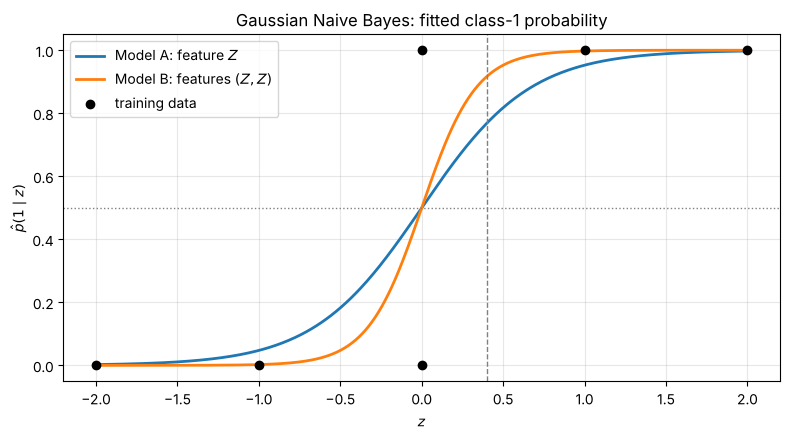

In [4]:
z = np.linspace(-2, 2, 400)
pA_curve = model_A.predict_proba(z.reshape(-1, 1))[:, 1]
pB_curve = model_B.predict_proba(np.column_stack([z, z]))[:, 1]

plt.figure(figsize=(8, 4.5))
plt.plot(z, pA_curve, lw=2, label="Model A: feature $Z$")
plt.plot(z, pB_curve, lw=2, label="Model B: features $(Z, Z)$")
plt.scatter(Z, Y, c="k", zorder=3, label="training data")
plt.axhline(0.5, color="gray", ls=":", lw=1)
plt.axvline(0.4, color="gray", ls="--", lw=1)
plt.xlabel("$z$"); plt.ylabel(r"$\hat p(1\mid z)$")
plt.title("Gaussian Naive Bayes: fitted class-1 probability")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

Both curves cross $0.5$ at $z=0$, so the two models make the **same class decisions**. Model B is steeper: its probabilities are pushed further towards $0$ and $1$.

### c. The log posterior odds double

**Proof.** In Model B the two features are identical, so for each class $k$ both coordinates have the same fitted mean and variance as in Model A: $\hat\mu_{k1}=\hat\mu_{k2}=\hat\mu_k$, $\hat\sigma^2_{k1}=\hat\sigma^2_{k2}=\hat\sigma^2_k$. The priors are also the same. Using the Naive Bayes factorization at the input $(z,z)$:
$$\log\frac{\hat p_B(1\mid z,z)}{\hat p_B(0\mid z,z)}
=\log\frac{\hat\pi_1}{\hat\pi_0}+\sum_{j=1}^{2}\log\frac{\mathcal N(z;\hat\mu_1,\hat\sigma_1^2)}{\mathcal N(z;\hat\mu_0,\hat\sigma_0^2)}
=\log\frac{\hat\pi_1}{\hat\pi_0}+2\log\frac{\mathcal N(z;\hat\mu_1,\hat\sigma_1^2)}{\mathcal N(z;\hat\mu_0,\hat\sigma_0^2)} .$$
Since $\hat\pi_0=\hat\pi_1=\frac12$, the prior term is $\log 1=0$, hence
$$\log\text{odds}_B(z)=2\,\log\text{odds}_A(z)\qquad(\text{here } 6z \text{ vs } 3z).$$
The numerical check below confirms the ratio is $2$ at every $z\ne0$.

log-odds A at z=0.4: 1.2
log-odds B at z=0.4: 2.4
ratio log-odds_B / log-odds_A: min = 2.000000, max = 2.000000


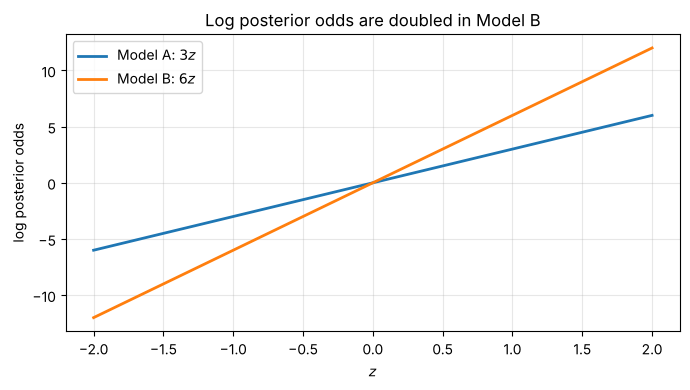

In [5]:
z_chk = np.linspace(-2, 2, 401)
z_chk = z_chk[np.abs(z_chk) > 1e-9]        # log-odds is 0 at z = 0
lpA = model_A.predict_log_proba(z_chk.reshape(-1, 1))
lpB = model_B.predict_log_proba(np.column_stack([z_chk, z_chk]))
odds_A = lpA[:, 1] - lpA[:, 0]
odds_B = lpB[:, 1] - lpB[:, 0]
ratio = odds_B / odds_A

print("log-odds A at z=0.4:", round(float(model_A.predict_log_proba([[0.4]])[0] @ [-1, 1]), 4))
print("log-odds B at z=0.4:", round(float(model_B.predict_log_proba([[0.4, 0.4]])[0] @ [-1, 1]), 4))
print(f"ratio log-odds_B / log-odds_A: min = {ratio.min():.6f}, max = {ratio.max():.6f}")

plt.figure(figsize=(7, 4))
plt.plot(z_chk, odds_A, lw=2, label="Model A: $3z$")
plt.plot(z_chk, odds_B, lw=2, label="Model B: $6z$")
plt.xlabel("$z$"); plt.ylabel("log posterior odds")
plt.title("Log posterior odds are doubled in Model B")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

**Why Model B is more confident without new information.** The second feature is an exact copy of the first, so it carries no new information about $Y$. But Naive Bayes assumes the features are **conditionally independent given the class**, so it treats the copy as an independent second piece of evidence and adds its log-likelihood ratio again. The same evidence is counted twice, which doubles the log odds and pushes the probabilities towards $0$ and $1$.

The independence assumption is badly violated here (the two features are perfectly correlated). The class decisions are unchanged, but the probabilities are **overconfident**, so log-loss would punish Model B heavily for any point it gets wrong. Correlated or duplicated features are a known weakness of Naive Bayes.

## Task 2. LDA and QDA with one additional observation

Both are generative Gaussian models with fixed priors $\pi_0=\pi_1=\frac12$:

* **LDA:** $X\mid Y=k\sim\mathcal N(\mu_k,\sigma^2)$ with a **common** (pooled) variance. In one dimension the log posterior odds are affine:
$$\log\frac{\hat p(1\mid x)}{\hat p(0\mid x)}=\frac{\hat\mu_1-\hat\mu_0}{\hat\sigma^2}\Big(x-\frac{\hat\mu_0+\hat\mu_1}{2}\Big)+\log\frac{\pi_1}{\pi_0}.$$
With equal priors the boundary is the midpoint $\frac{\hat\mu_0+\hat\mu_1}{2}$, and the slope is $\frac{\hat\mu_1-\hat\mu_0}{\hat\sigma^2}$.
* **QDA:** $X\mid Y=k\sim\mathcal N(\mu_k,\sigma_k^2)$ with a **separate** variance per class. The log odds are quadratic:
$$\log\frac{\hat p(1\mid x)}{\hat p(0\mid x)}=-\tfrac12\log\frac{\hat\sigma_1^2}{\hat\sigma_0^2}-\frac{(x-\hat\mu_1)^2}{2\hat\sigma_1^2}+\frac{(x-\hat\mu_0)^2}{2\hat\sigma_0^2}+\log\frac{\pi_1}{\pi_0}.$$

In [6]:
x0 = np.array([-2, -1, 0, 1, 2], dtype=float)          # class 0
x1 = np.array([1.5, 2.5, 3.5, 4.5, 5.5])                # class 1
x_val = np.array([-2.5, -0.5, 0.5, 2.5, 3.5, 5.0])
y_val = np.array([0, 0, 0, 1, 1, 1])
PRIORS = [0.5, 0.5]

def make_data(extra=None):
    X = np.r_[x0, x1]
    y = np.r_[np.zeros(len(x0), int), np.ones(len(x1), int)]
    if extra is not None:
        X = np.r_[X, extra[0]]
        y = np.r_[y, extra[1]]
    return X.reshape(-1, 1), y

def fit_both(X, y):
    lda = LinearDiscriminantAnalysis(priors=PRIORS).fit(X, y)
    qda = QuadraticDiscriminantAnalysis(priors=PRIORS, store_covariance=True).fit(X, y)
    return lda, qda

X_before, y_before = make_data()
X_after,  y_after  = make_data(extra=(9.5, 1))

lda_b, qda_b = fit_both(X_before, y_before)
lda_a, qda_a = fit_both(X_after,  y_after)
models = {("LDA", "before"): lda_b, ("QDA", "before"): qda_b,
          ("LDA", "after"):  lda_a, ("QDA", "after"):  qda_a}
print("Training points before:", len(y_before), " after:", len(y_after))

Training points before: 10  after: 11


### a. Validation log-loss on the initial training data

In [7]:
def val_log_loss(model):
    p1 = model.predict_proba(x_val.reshape(-1, 1))[:, 1]
    return log_loss(y_val, p1, labels=[0, 1])

for name in ["LDA", "QDA"]:
    print(f"{name} (initial data): validation log-loss = {val_log_loss(models[(name, 'before')]):.4f}")

LDA (initial data): validation log-loss = 0.0689
QDA (initial data): validation log-loss = 0.0689


On the initial data both classes have exactly the same spread (each is 5 equally spaced points), so the QDA class variances are equal and **QDA reduces to LDA**: the two log-losses coincide.

### b. Adding $(x,y)=(9.5,1)$: before/after table

In [8]:
table = pd.DataFrame(
    {"before": [val_log_loss(lda_b), val_log_loss(qda_b)],
     "after adding (9.5, 1)": [val_log_loss(lda_a), val_log_loss(qda_a)]},
    index=["LDA", "QDA"])
table["change"] = table["after adding (9.5, 1)"] - table["before"]
table.round(4)

,before,"after adding (9.5, 1)",change
LDA,0.0689,0.1885,0.1195
QDA,0.0689,0.1366,0.0677


To explain these numbers we look at the fitted means and variances. For LDA the pooled variance used for prediction is recovered from the fitted slope, $\hat\sigma^2=(\hat\mu_1-\hat\mu_0)/\text{coef}$; for QDA the class variances are stored in `covariance_`.

In [9]:
grid = np.linspace(-6, 10, 3201)

wide = np.linspace(-20, 20, 40001)   # wider than the plot, to catch every boundary

def boundaries(model):
    p = model.predict_proba(wide.reshape(-1, 1))[:, 1] - 0.5
    idx = np.where((p[:-1] < 0) != (p[1:] < 0))[0]       # sign changes of p - 0.5
    return ", ".join(f"{wide[i]:.2f}" for i in idx) or "none"

rows = []
for (name, when), m in models.items():
    mu0, mu1 = m.means_.ravel()
    if name == "LDA":
        pooled = (mu1 - mu0) / m.coef_[0, 0]
        var0 = var1 = pooled
    else:
        var0, var1 = (float(c.ravel()[0]) for c in m.covariance_)
    rows.append(dict(model=name, data=when, mu0=mu0, mu1=mu1,
                     var0=var0, var1=var1,
                     boundary=boundaries(m), val_log_loss=val_log_loss(m)))
params = pd.DataFrame(rows).set_index(["model", "data"]).sort_index(level=[0, 1], ascending=[True, False])
params.round(4)

mu0  mu1    var0    var1     boundary  val_log_loss
model data                                                       
LDA   before  0.0  3.5  2.0000  2.0000         1.75        0.0689
      after   0.0  4.5  4.5455  4.5455         2.25        0.1885
QDA   before  0.0  3.5  2.0000  2.0000         1.75        0.0689
      after   0.0  4.5  2.0000  6.6667  -5.91, 2.05        0.1366

In [10]:
pred = pd.DataFrame({"x": x_val, "y": y_val})
for (name, when), m in models.items():
    pred[f"{name} {when}"] = m.predict_proba(x_val.reshape(-1, 1))[:, 1]
print("Validation probabilities p(1|x):")
print(pred.round(4).to_string(index=False))

Validation probabilities p(1|x):
   x  y  LDA before  QDA before  LDA after  QDA after
-2.5  0      0.0006      0.0006     0.0090     0.0621
-0.5  0      0.0191      0.0191     0.0617     0.0821
 0.5  0      0.1009      0.1009     0.1503     0.1494
 2.5  1      0.7879      0.7879     0.5616     0.6594
 3.5  1      0.9553      0.9553     0.7751     0.9157
 5.0  1      0.9966      0.9966     0.9383     0.9964


### c. Class-1 probability curves on $[-6,10]$

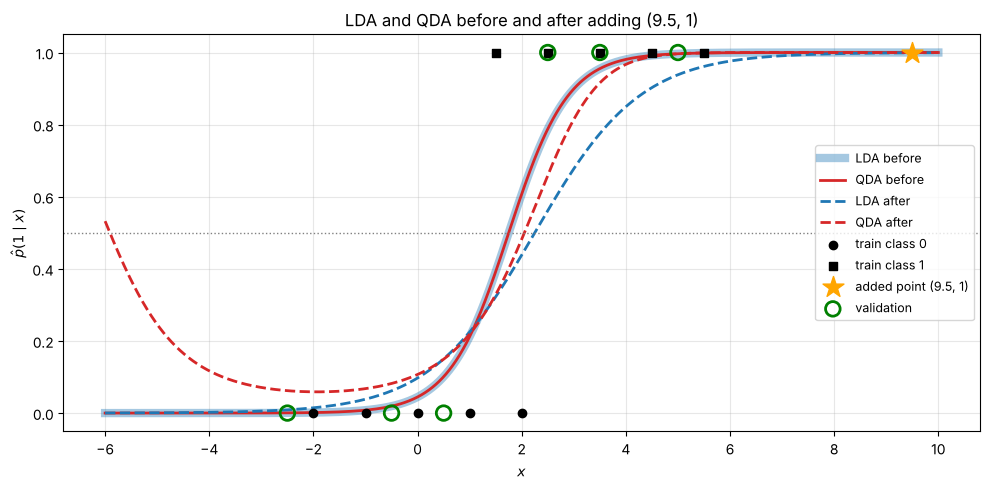

In [11]:
# LDA and QDA coincide before the addition, so LDA "before" is drawn wide and pale underneath
styles = {("LDA", "before"): dict(color="#1f77b4", ls="-",  lw=6, alpha=0.4),
          ("LDA", "after"):  dict(color="#1f77b4", ls="--", lw=2),
          ("QDA", "before"): dict(color="#d62728", ls="-",  lw=2),
          ("QDA", "after"):  dict(color="#d62728", ls="--", lw=2)}

plt.figure(figsize=(10, 5))
for key, m in models.items():
    plt.plot(grid, m.predict_proba(grid.reshape(-1, 1))[:, 1],
             label=f"{key[0]} {key[1]}", **styles[key])
plt.scatter(x0, np.zeros_like(x0), c="k", marker="o", zorder=3, label="train class 0")
plt.scatter(x1, np.ones_like(x1), c="k", marker="s", zorder=3, label="train class 1")
plt.scatter([9.5], [1], c="orange", marker="*", s=250, zorder=4, label="added point (9.5, 1)")
plt.scatter(x_val, y_val, facecolors="none", edgecolors="green", s=110, lw=2, zorder=3,
            label="validation")
plt.axhline(0.5, color="gray", ls=":", lw=1)
plt.xlabel("$x$"); plt.ylabel(r"$\hat p(1\mid x)$")
plt.title("LDA and QDA before and after adding (9.5, 1)")
plt.legend(loc="center right", fontsize=9); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

**Explanation using the fitted variances** (numbers in the parameter table above).

**Before the addition.** Both classes have the same spread, so $\hat\sigma_0^2=\hat\sigma_1^2$ and QDA coincides with LDA. The two solid curves lie on top of each other: one logistic curve with boundary at the midpoint $\frac{0+3.5}{2}=1.75$.

**What the new point does.** $x=9.5$ lies far to the right of the other class-1 points. It moves the class-1 mean from $3.5$ to $\frac{17.5+9.5}{6}=4.5$, and, more importantly, it inflates the class-1 spread: the squared deviation $(9.5-4.5)^2=25$ is larger than all other class-1 deviations combined ($9+4+1+0+1=15$). Class 0 is unchanged.

**LDA after.** LDA must use one pooled variance, so the increase in class 1 spread is spread over both classes and $\hat\sigma^2$ roughly doubles.
* The boundary moves right to the new midpoint $\frac{0+4.5}{2}=2.25$.
* The slope $\frac{\hat\mu_1-\hat\mu_0}{\hat\sigma^2}$ decreases, because the larger variance outweighs the larger mean gap, so the curve becomes **flatter**.
* Result: $\hat p(1\mid x)$ falls at the class-1 validation points ($x=2.5$ is now barely above $0.5$) and rises at the class-0 points. LDA validation log-loss increases.

**QDA after.** QDA gives each class its own variance. $\hat\sigma_0^2$ stays the same, only $\hat\sigma_1^2$ grows (by more than a factor of 3).
* Class 0 keeps its sharp density, so near the class-0 data QDA stays confident, and class 1 keeps a mean near its own points, so the validation points at $3.5$ and $5$ keep high class-1 probability and $x=2.5$ stays on the correct side. QDA's log-loss increases, but less than LDA's.
* Because $\hat\sigma_1^2>\hat\sigma_0^2$, the $x^2$ coefficient of the log odds, $\frac1{2\hat\sigma_0^2}-\frac1{2\hat\sigma_1^2}$, is positive. The log odds are an upward parabola, so $\hat p(1\mid x)\to1$ as $x\to\pm\infty$. The wide class-1 Gaussian eventually beats the narrow class-0 Gaussian in **both tails**, which creates a **second decision boundary** on the far left, near $x\approx-6$ (see the `boundary` column; the dashed red curve already rises at the left edge of the plot): QDA would assign very negative $x$ to class 1, even though all class-1 data lie on the right. This is an artifact of the Gaussian tails, not of the data.

**Summary.** One outlier changes only the class-1 variance. LDA spreads this change over both classes (flatter curve, shifted boundary, higher log-loss). QDA isolates it in class 1, so it is less affected on the validation set, but its quadratic log odds produce a spurious second boundary far from the data.

*Note:* depending on the scikit-learn version, the fitted variances use the divisor $n$ (maximum likelihood, as in the lecture) or $n-1$ / $n-K$ (unbiased). The numbers change slightly, but every conclusion above is the same.